# 10 — Circuitos dinámicos: corrección de errores y tiempo real

**Curso ECCI 2026 · Computación cuántica**

Toda la serie viene mostrando lo mismo desde ángulos distintos: el ruido
tiene
un techo. La contracción del vector de Bloch en el `01`, la coherencia de
GHZ
cayendo en el `02`, el ruido plano de Shor en el `09`. Y la pregunta que
queda
colgada es siempre la misma:

> ¿Y entonces cómo se sale de esto?

La respuesta es **corrección cuántica de errores**, y no se puede
implementar
con circuitos estáticos. Hace falta medir a mitad de circuito, decidir en
función del resultado, y actuar — todo mientras los otros qubits siguen
vivos.
Eso son los **circuitos dinámicos**, y Heron los soporta de verdad.

Recorrido:

1. Qué instrucciones de control de flujo tiene el chip, y **cuánto duran**.
2. `reset`: reutilizar qubits.
3. Corregir sin clonar: la idea del **síndrome**.
4. El código de repetición de 3 qubits, con corrección en tiempo real.
5. **El dual de fase**, y por qué ningún código de 3 qubits alcanza.
6. QPE iterativa en un solo circuito: el ahorro de QPU, medido.
7. **El cronograma real del chip** (`scheduler_timing`).

## Preámbulo: entorno

Esta celda no hace nada en el entorno local (el env `quantum`, que ya tiene
todo instalado). Solo actúa si el notebook corre en **Google Colab**, donde
instala lo que falta.

`plotly` e `ipywidgets` vienen con Colab, así que no se instalan.

**Sobre `utils.py`:** los notebooks importan ese módulo, que en el entorno
local está en la misma carpeta. En Colab la celda lo **baja solo** de un
archivo de Drive compartido como "cualquiera con el link puede ver", así que
funciona para cualquiera que abra el notebook sin que tenga que autenticarse.

Dos detalles de esa descarga:

- se usa el endpoint `drive.usercontent.google.com`, porque la URL clásica
  `uc?export=download` devuelve la página de aviso de antivirus en vez del
  archivo;
- solo baja si `utils` no está ya disponible, de modo que una **subida manual
  al panel de archivos tiene prioridad** sobre la copia de Drive.

Si el archivo de Drive se actualiza con *Administrar versiones*, el ID y el
link se mantienen, y los notebooks siguen apuntando al lugar correcto.

In [1]:
import importlib.util
import sys

try:                      # find_spec("google.colab") falla si no existe el padre
    import google.colab   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !pip install qiskit
    !pip install qiskit-ibm-runtime
    !pip install qiskit_aer
    !pip install pylatexenc

    # utils.py desde Drive, compartido como "cualquiera con el link puede ver".
    # Se usa el endpoint drive.usercontent, que entrega el archivo directo; la
    # URL clásica uc?export=download devuelve la página de aviso de antivirus.
    # Solo se baja si no está ya presente, así una subida manual tiene prioridad.
    UTILS_ID = "1_VyKXtDMVqnJHcGepeARhoEY4tikLSDg"
    if importlib.util.find_spec("utils") is None:
        !wget -q -O utils.py "https://drive.usercontent.google.com/download?id=$UTILS_ID&export=download&confirm=t"
        importlib.invalidate_caches()
        if importlib.util.find_spec("utils") is None:
            print("No se pudo bajar utils.py: subirlo a mano desde el panel de archivos.")
        else:
            print("utils.py descargado de Drive")
else:
    print("entorno local: no hay nada que instalar")

try:
    import utils
    print(f"utils.py versión {utils.__version__}")
except ImportError:
    print("utils.py todavía no está disponible")

entorno local: no hay nada que instalar


utils.py versión 2026-09-19


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit import (ClassicalRegister, QuantumCircuit, QuantumRegister, transpile)
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error
from qiskit_ibm_runtime.fake_provider import FakeFez

import plotly.io as pio

import utils

utils.estilo()
pio.renderers.default = "plotly_mimetype"
fez = FakeFez()
MARCAS = "①②③④⑤⑥⑦⑧⑨"
BASE_SIM = ["sx", "x", "rz", "h", "id", "cx", "cz", "measure", "reset",
            "if_else", "switch_case"]


def marca(qc, n):
    qc.barrier(label=MARCAS[n - 1])
    return qc


print("listo")

listo


## Autenticación (opcional, y en memoria)

In [3]:
from getpass import getpass

from qiskit_ibm_runtime import QiskitRuntimeService

CRN = "crn:v1:bluemix:public:quantum-computing:us-east:a/1a958fc8c19b451ba71d1d0d94d52a44:9153727a-cc43-46be-a974-dfe1f29b4bcb::"

AUTENTICAR = False

service = None
if AUTENTICAR:
    service = QiskitRuntimeService(channel="ibm_cloud",
                                   token=getpass("API key: "),
                                   instance=CRN)
    print([b.name for b in service.backends()])
else:
    print("sin autenticar — el notebook corre entero en simulador")

sin autenticar — el notebook corre entero en simulador


---
# 1. Qué puede hacer el chip, y cuánto cuesta

Esto no es una promesa de marketing: son las instrucciones que declara el
*target* de Heron, al mismo nivel que `cz` o `sx`.

In [4]:
ops = sorted(fez.target.operation_names)
control = [o for o in ops if o in ("if_else", "switch_case", "for_loop",
                                   "while_loop", "reset", "delay")]
print("todas las operaciones del chip:", ops)
print("\nde control de flujo:", control)
print("\nNO está:", [o for o in ("while_loop",) if o not in ops],
      "← no hay repetición no acotada")

print(f"\ndt (un ciclo de scheduling) = {fez.dt * 1e9:.2f} ns\n")
duraciones = {}
for op in ("rz", "sx", "x", "cz", "measure", "reset"):
    try:
        ds = [p.duration for p in fez.target[op].values() if p and p.duration]
        if ds:
            duraciones[op] = float(np.median(ds))
    except KeyError:
        pass
base_sx = duraciones.get("sx", 1)
print(f"{'instrucción':<12} {'duración':>10} {'en dt':>8} {'× una sx':>10}")
for op, d in sorted(duraciones.items(), key=lambda kv: kv[1]):
    print(f"{op:<12} {d * 1e9:>8.0f} ns {d / fez.dt:>8.0f} {d / base_sx:>10.1f}")

todas las operaciones del chip: ['cz', 'delay', 'for_loop', 'id', 'if_else', 'measure', 'reset', 'rz', 'switch_case', 'sx', 'x']

de control de flujo: ['delay', 'for_loop', 'if_else', 'reset', 'switch_case']

NO está: ['while_loop'] ← no hay repetición no acotada

dt (un ciclo de scheduling) = 4.00 ns

instrucción    duración    en dt   × una sx
sx                 24 ns        6        1.0
x                  24 ns        6        1.0
cz                 84 ns       21        3.5
measure          1560 ns      390       65.0
reset            1584 ns      396       66.0


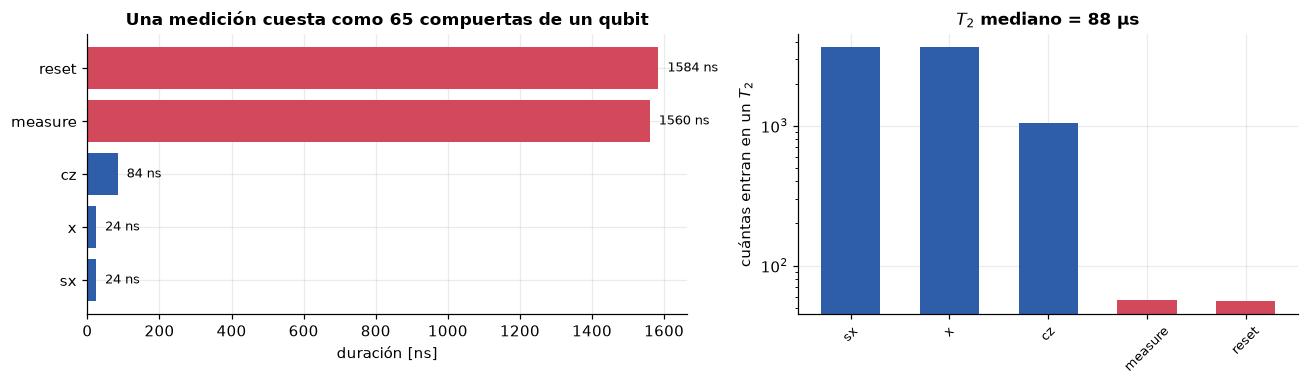

T1 mediano = 145 µs   ·   T2 mediano = 88 µs
en un T2 entran ~3665 compuertas de un qubit, pero solo ~56 mediciones


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6),
                               gridspec_kw={"width_ratios": [1.2, 1]})
ops_o = sorted(duraciones.items(), key=lambda kv: kv[1])
colores = [utils.COLOR_RUIDO if o in ("measure", "reset") else utils.COLOR_IDEAL
           for o, _ in ops_o]
ax1.barh([o for o, _ in ops_o], [d * 1e9 for _, d in ops_o], color=colores)
ax1.set_xlabel("duración [ns]")
ax1.set_title("Una medición cuesta como 65 compuertas de un qubit")
for i, (o, d) in enumerate(ops_o):
    ax1.text(d * 1e9 + 25, i, f"{d * 1e9:.0f} ns", va="center", fontsize=8.5)

t1 = float(np.median([fez.properties().t1(q) for q in range(fez.num_qubits)]))
t2 = float(np.median([fez.properties().t2(q) for q in range(fez.num_qubits)]))
cuantas = {o: t2 / d for o, d in duraciones.items()}
ax2.bar(range(len(ops_o)), [cuantas[o] for o, _ in ops_o],
        color=colores, width=0.6)
ax2.set_yscale("log")
ax2.set_xticks(range(len(ops_o)))
ax2.set_xticklabels([o for o, _ in ops_o], rotation=45, fontsize=8.5)
ax2.set_ylabel("cuántas entran en un $T_2$")
ax2.set_title(f"$T_2$ mediano = {t2 * 1e6:.0f} µs")
utils.layout(fig)
plt.show()

print(f"T1 mediano = {t1 * 1e6:.0f} µs   ·   T2 mediano = {t2 * 1e6:.0f} µs")
print(f"en un T2 entran ~{t2 / duraciones['sx']:.0f} compuertas de un qubit, "
      f"pero solo ~{t2 / duraciones['measure']:.0f} mediciones")

**Ese último número es el presupuesto real de un circuito dinámico.** Se
pueden encadenar miles de compuertas de un qubit dentro de la coherencia,
pero
apenas unas decenas de mediciones. Cada medición a mitad de circuito consume
una fracción grande de la vida del qubit, y además hay que sumarle el tiempo
que la electrónica tarda en *decidir* — que no está en esta tabla y que
vamos
a medir en la §7.

### Una advertencia de flujo de trabajo

Qiskit permite además **variables clásicas en tiempo real** (`add_var` y
`store`), que el chip soporta. Pero **Aer no las simula**: fallan con
`AttributeError`. Como en este curso todo se depura en simulador antes de
gastar QPU, quedan fuera. Con `if_else` y `switch_case` sobre registros
clásicos alcanza para todo lo que sigue, y eso sí funciona en los dos lados.

---
# 2. `reset`: reutilizar un qubit

La instrucción más simple de las dinámicas. `reset` mide el qubit y, si dio
1,
le aplica una $X$: lo devuelve a $|0\rangle$ pase lo que pase. Cuesta lo
mismo
que una medición (~1.6 µs), pero permite hacer con **un** qubit lo que
necesitaría varios.

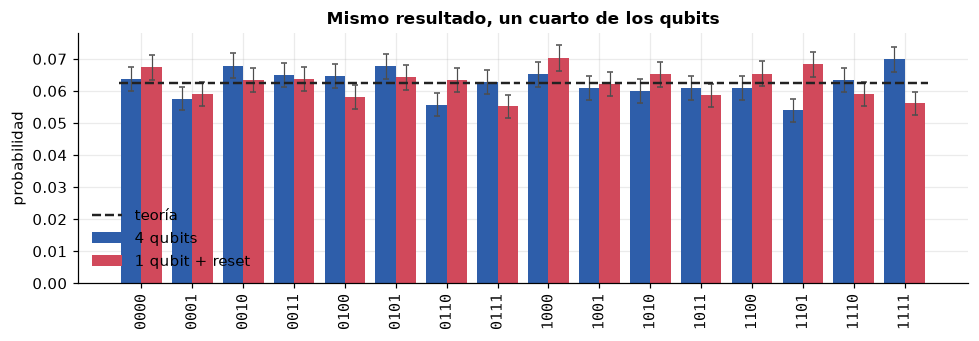

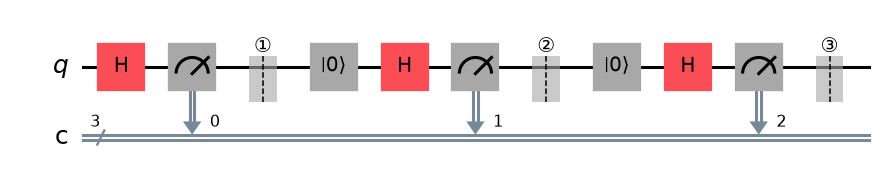

sin reset: 4 qubits, profundidad 2
con reset: 1 qubit,  profundidad 11
el reset cuesta 1584 ns cada uno: se cambian qubits por tiempo


In [6]:
def sin_reset(n: int) -> QuantumCircuit:
    """n monedas independientes, un qubit por moneda."""
    qc = QuantumCircuit(n, n)
    qc.h(range(n))
    marca(qc, 1)
    qc.measure(range(n), range(n))
    return qc


def con_reset(n: int) -> QuantumCircuit:
    """Las mismas n monedas, reutilizando UN qubit."""
    qc = QuantumCircuit(1, n)
    for k in range(n):
        if k:
            qc.reset(0)
        qc.h(0)
        qc.measure(0, k)
        marca(qc, min(k + 1, 9))
    return qc


N = 4
c_sin = utils.correr_ideal(sin_reset(N), shots=4096)
c_con = utils.correr_ideal(con_reset(N), shots=4096)

fig, ax = plt.subplots(figsize=(9, 3.2))
utils.comparar_conteos({f"{N} qubits": c_sin, "1 qubit + reset": c_con},
                       claves=utils.claves_completas(N), ax=ax,
                       teoria={k: 1 / 2 ** N for k in utils.claves_completas(N)},
                       titulo="Mismo resultado, un cuarto de los qubits")
utils.layout(fig)
plt.show()

display(con_reset(3).draw("mpl", style="iqp", fold=-1))
print(f"sin reset: {sin_reset(N).num_qubits} qubits, profundidad {sin_reset(N).depth()}")
print(f"con reset: {con_reset(N).num_qubits} qubit,  profundidad {con_reset(N).depth()}")
print(f"el reset cuesta {duraciones['reset'] * 1e9:.0f} ns cada uno: "
      f"se cambian qubits por tiempo")

**Es un intercambio, no una ganancia gratis.** Se ahorran qubits y se paga
en
profundidad y en tiempo. Conviene cuando los qubits son el recurso escaso o
cuando el circuito es corto; no conviene si ya se está peleando contra $T_2$.

En la §6 el `reset` va a hacer algo más interesante: permitir que la QPE
iterativa del notebook `08` —que necesitaba $n$ jobs separados— entre entera
en **uno**.

---
# 3. Corregir sin clonar

Acá está el problema conceptual, y es serio.

La corrección clásica de errores es trivial: **se copia** el bit tres veces y
se vota por mayoría. `0 → 000`; si llega `010`, ganó el 0.

Con qubits eso está **prohibido**. El teorema de no-clonación (notebook
`03`)
dice que no existe la máquina $|\psi\rangle \to |\psi\rangle|\psi\rangle$. Y
hay un segundo problema, igual de grave: para votar habría que **mirar** los
tres qubits, y mirarlos los colapsa. La medición destruiría justamente lo
que
queremos proteger.

### La salida: medir la paridad, no el estado

El truco tiene dos partes.

**(a) Entrelazar en vez de copiar.** El circuito
$|\psi\rangle|00\rangle \to \alpha|000\rangle + \beta|111\rangle$ **no** es
una
copia —las copias serían $(\alpha|0\rangle+\beta|1\rangle)^{\otimes 3}$, que
es
otra cosa— pero distribuye la información en los tres qubits de modo que un
error en uno solo se pueda detectar.

**(b) Preguntar solo por la paridad.** En vez de "¿cuánto vale el qubit 0?",
preguntamos "¿los qubits 0 y 1 son **iguales**?". Esa pregunta:

- tiene respuesta sí/no, o sea un bit,
- **no distingue $|000\rangle$ de $|111\rangle$**, así que no revela nada
sobre
  $\alpha$ y $\beta$,
- y por lo tanto **no colapsa la superposición**.

Con dos preguntas de paridad —$(q_0,q_1)$ y $(q_1,q_2)$— alcanza para ubicar
cuál de los tres qubits se dio vuelta:

| $q_0 q_1$ | $q_1 q_2$ | síndrome | diagnóstico |
|---|---|---|---|
| iguales | iguales | `00` | sin error |
| **distintos** | iguales | `01` | se dio vuelta $q_0$ |
| **distintos** | **distintos** | `11` | se dio vuelta $q_1$ |
| iguales | **distintos** | `10` | se dio vuelta $q_2$ |

Eso es el **síndrome**: información sobre el *error*, no sobre el *estado*.

---
# 4. El código de repetición, con corrección en tiempo real

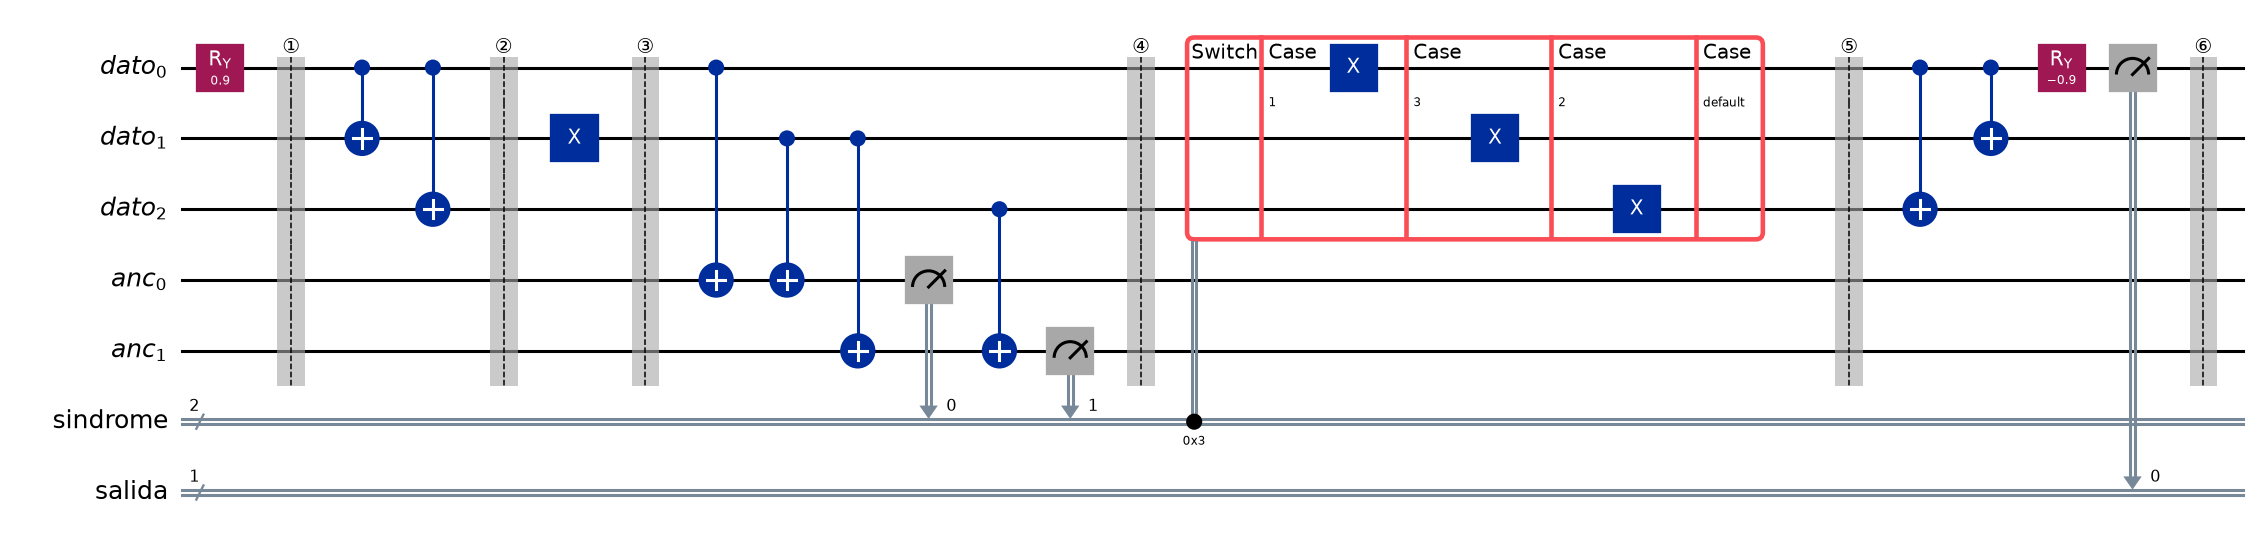

In [7]:
def codigo_bitflip(theta=0.0, error_en=None, corregir=True) -> QuantumCircuit:
    """Protege Ry(theta)|0> contra un bit-flip, con corrección por switch.

    error_en: 0, 1 o 2 para inyectar una X a mano, None para no inyectar nada.
    """
    d = QuantumRegister(3, "dato")
    a = QuantumRegister(2, "anc")
    s = ClassicalRegister(2, "sindrome")
    o = ClassicalRegister(1, "salida")
    qc = QuantumCircuit(d, a, s, o)

    qc.ry(theta, d[0])
    marca(qc, 1)

    qc.cx(d[0], d[1])                      # codificar: entrelazar, no copiar
    qc.cx(d[0], d[2])
    marca(qc, 2)

    if error_en is not None:               # el error que queremos corregir
        qc.x(d[error_en])
    marca(qc, 3)

    qc.cx(d[0], a[0]); qc.cx(d[1], a[0])   # paridad de (q0,q1) → ancilla 0
    qc.cx(d[1], a[1]); qc.cx(d[2], a[1])   # paridad de (q1,q2) → ancilla 1
    qc.measure(a, s)
    marca(qc, 4)

    if corregir:
        with qc.switch(s) as caso:         # la decisión, en tiempo real
            with caso(0b01):
                qc.x(d[0])
            with caso(0b11):
                qc.x(d[1])
            with caso(0b10):
                qc.x(d[2])
            with caso(caso.DEFAULT):
                pass
    marca(qc, 5)

    qc.cx(d[0], d[2]); qc.cx(d[0], d[1])   # decodificar
    qc.ry(-theta, d[0])                    # deshacer la preparación
    qc.measure(d[0], o)                    # si todo salió bien: 0
    marca(qc, 6)
    return qc


display(codigo_bitflip(0.9, error_en=1).draw("mpl", style="iqp", fold=-1))

### La cuenta, etapa por etapa (error en $q_1$)

**①** $|\psi_1\rangle = (\alpha|0\rangle +
\beta|1\rangle)_{d_0}|00\rangle_{d_1d_2}$,
con $\alpha = \cos(\theta/2)$, $\beta = \sin(\theta/2)$.

**②** Dado que se aplican las dos CNOT de codificación:
$$|\psi_2\rangle = \alpha|000\rangle + \beta|111\rangle .$$
**No son copias.** Un estado con tres copias sería
$(\alpha|0\rangle+\beta|1\rangle)^{\otimes3}$, que tiene ocho términos. Este
tiene dos, y está entrelazado.

**③** Dado que ocurre el error $X$ sobre $d_1$:
$$|\psi_3\rangle = \alpha|010\rangle + \beta|101\rangle .$$
**$\alpha$ y $\beta$ siguen intactos**: el error movió el estado a
otro subespacio, no destruyó la información.

**④** Dado que se miden las dos paridades: los dos términos dan el **mismo**
síndrome —en $|010\rangle$, $q_0\neq q_1$ y $q_1 \neq q_2$; en
$|101\rangle$,
igual— así que la medición devuelve `11` **con certeza y sin colapsar la
superposición**. El estado sigue siendo $\alpha|010\rangle +
\beta|101\rangle$.

Esa es la magia del método: el síndrome es el mismo para los dos términos,
así
que medirlo no los distingue.

**⑤** Dado que el `switch` lee `11` y aplica $X$ sobre $d_1$:
$$|\psi_5\rangle = \alpha|000\rangle + \beta|111\rangle .$$
El error se deshizo. **Esta compuerta se decide dentro del chip, mientras el
circuito corre** — no hay forma de hacerlo en post-proceso, porque los
qubits
tienen que seguir viviendo para el paso siguiente.

**⑥** Dado que se decodifica y se deshace la preparación: el qubit $d_0$
vuelve
a $|0\rangle$ y la medición final da **0**. Cualquier `1` es un fallo
lógico.

In [8]:
sim = AerSimulator()
SHOTS = 8192
print(f"{'error inyectado':<18} {'síndrome':>12} {'P(fallo) con corrección':>26} "
      f"{'sin corrección':>16}")
for err in (None, 0, 1, 2):
    c_ok = utils.correr_ideal(codigo_bitflip(0.9, err, True), shots=SHOTS)
    c_no = utils.correr_ideal(codigo_bitflip(0.9, err, False), shots=SHOTS)
    sind = max(c_ok, key=c_ok.get).split()[1]
    f_ok = sum(v for k, v in c_ok.items() if k.split()[0] == "1") / SHOTS
    f_no = sum(v for k, v in c_no.items() if k.split()[0] == "1") / SHOTS
    print(f"{str(err):<18} {sind:>12} {f_ok:>26.4f} {f_no:>16.4f}")

error inyectado        síndrome    P(fallo) con corrección   sin corrección
None                         00                     0.0000           0.0000


0                            01                     0.0000           0.3950
1                            11                     0.0000           0.0000


2                            10                     0.0000           0.0000


La columna del síndrome reproduce exactamente la tabla teórica: `00`, `01`,
`11`, `10` para ningún error, $q_0$, $q_1$, $q_2$.

**Pero la última columna tiene una trampa.** Sin
corrección, el error en $q_1$ y el de $q_2$ **tampoco hacen fallar la
salida**. La razón: la decodificación devuelve la información a $d_0$ con
CNOTs que no propagan hacia atrás, así que un bit-flip en $d_1$ o $d_2$ se
pierde en el camino. El único que rompe la salida sin corregir es el de
$d_0$.

Si uno mide "¿falló la salida?" y nada más, **la demo exagera lo que la
corrección está haciendo**. Lo honesto es mirar el síndrome, que sí detecta
los tres, y medir el error lógico con ruido real en todos los qubits, que es
lo que sigue.

### Elegir el error y miremos el síndrome

In [9]:
def explorar_sindrome(error_en="ninguno", corregir=True):
    err = None if error_en == "ninguno" else int(error_en)
    c = utils.correr_ideal(codigo_bitflip(0.9, err, bool(corregir)), shots=4096)
    sind, salida = {}, {}
    for k, v in c.items():
        out, s = k.split()
        sind[s] = sind.get(s, 0) + v
        salida[out] = salida.get(out, 0) + v
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3),
                                   gridspec_kw={"width_ratios": [1.4, 1]})
    utils.comparar_conteos({"medido": sind}, claves=["00", "01", "11", "10"],
                           ax=ax1, titulo="síndrome leído")
    ax1.set_xticklabels(["00\nsin error", "01\nerror en $q_0$",
                         "11\nerror en $q_1$", "10\nerror en $q_2$"], fontsize=8)
    ax1.set_xlabel("")
    utils.comparar_conteos({"medido": salida}, claves=["0", "1"], ax=ax2,
                           titulo="salida lógica (0 = bien)")
    ax2.set_xlabel("")
    plt.show()
    esperado = {None: "00", 0: "01", 1: "11", 2: "10"}[err]
    print(f"error en {error_en} → síndrome esperado {esperado}, "
          f"leído {max(sind, key=sind.get)}   "
          f"· fallo lógico {salida.get('1', 0) / 4096:.4f}")


utils.deslizador(explorar_sindrome, error_en=["ninguno", "0", "1", "2"],
                 corregir=[True, False])

interactive(children=(Dropdown(description='error_en', options=('ninguno', '0', '1', '2'), value='ninguno'), D…

interactive(children=(Dropdown(description='error_en', options=('ninguno', '0', '1', '2'), value='ninguno'), D…

### La curva que justifica todo: error lógico contra error físico

Ahora el experimento serio. Ponemos ruido de bit-flip con probabilidad $p$
en
**todas** las compuertas, y comparamos:

- un qubit **sin proteger**, expuesto la misma cantidad de operaciones;
- el mismo qubit **dentro del código**.

La predicción, con síndrome perfecto, es que el código falla solo si se dan
vuelta **dos o más** qubits:

$$P_{\text{lógico}} = 3p^2(1-p) + p^3 = 3p^2 - 2p^3 .$$

Cuadrático contra lineal: para $p$ chico la diferencia es grande. Y el cruce
está en $p = 1/2$, donde ya no queda información que proteger.

código: profundidad 21 · control: 32 identidades


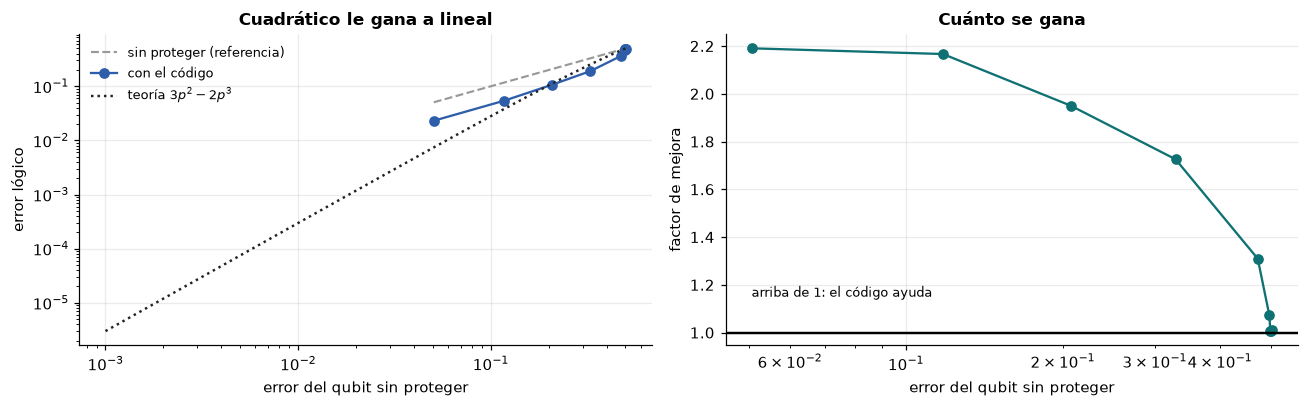

  p (físico)   error lógico    mejora
      0.0506         0.0231      2.2×
      0.1177         0.0544      2.2×
      0.2070         0.1061      2.0×
      0.3286         0.1904      1.7×
      0.4723         0.3607      1.3×
      0.4971         0.4638      1.1×
      0.4991         0.4960      1.0×
      0.5001         0.4967      1.0×
      0.5029         0.4969      1.0×


In [10]:
def ruido_pauli(p, pauli="X"):
    nm = NoiseModel()
    e1 = pauli_error([(pauli, p), ("I", 1 - p)])
    nm.add_all_qubit_quantum_error(e1, ["sx", "x", "rz", "h", "id"])
    nm.add_all_qubit_quantum_error(e1.tensor(e1), ["cx", "cz"])
    return nm


def desnudo(n_id, theta=0.0, base="Z"):
    """Control honesto: un qubit solo, con la MISMA exposición al ruido."""
    q = QuantumRegister(1, "dato"); o = ClassicalRegister(1, "salida")
    qc = QuantumCircuit(q, o)
    qc.ry(theta, 0) if base == "Z" else qc.h(0)
    for _ in range(n_id):
        qc.id(0)
    qc.ry(-theta, 0) if base == "Z" else qc.h(0)
    qc.measure(0, 0)
    return qc


# optimization_level=0: si no, el transpilador borra las identidades del control
t_cod = transpile(codigo_bitflip(0.0), basis_gates=BASE_SIM, optimization_level=0)
t_des = transpile(desnudo(t_cod.depth()), basis_gates=BASE_SIM, optimization_level=0)
print(f"código: profundidad {t_cod.depth()} · control: {t_des.depth()} identidades")

ps = np.array([0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5])
S = 20000
err_fis, err_log = [], []
for p in ps:
    simr = AerSimulator(noise_model=ruido_pauli(p, "X"))
    c1 = simr.run(t_cod, shots=S).result().get_counts()
    c2 = simr.run(t_des, shots=S).result().get_counts()
    err_log.append(sum(v for k, v in c1.items() if k.split()[0] == "1") / S)
    err_fis.append(sum(v for k, v in c2.items() if k == "1") / S)
err_fis, err_log = np.array(err_fis), np.array(err_log)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.loglog(err_fis, err_fis, "--", color="0.6", lw=1.4, label="sin proteger (referencia)")
ax1.loglog(err_fis, err_log, "o-", ms=6, color=utils.COLOR_IDEAL, label="con el código")
pp = np.logspace(-3, -0.3, 100)
ax1.loglog(pp, 3 * pp ** 2 - 2 * pp ** 3, ":", color=utils.COLOR_TEORIA, lw=1.6,
           label=r"teoría $3p^2 - 2p^3$")
ax1.set_xlabel("error del qubit sin proteger")
ax1.set_ylabel("error lógico")
ax1.set_title("Cuadrático le gana a lineal")
ax1.legend(fontsize=8.5)

ax2.semilogx(err_fis, err_fis / np.maximum(err_log, 1e-9), "o-", ms=6,
             color=utils.COLOR_HARD)
ax2.axhline(1, color="k", lw=1.6)
ax2.text(err_fis[0], 1.15, "arriba de 1: el código ayuda", fontsize=8.5)
ax2.set_xlabel("error del qubit sin proteger")
ax2.set_ylabel("factor de mejora")
ax2.set_title("Cuánto se gana")
utils.layout(fig)
plt.show()

print(f"{'p (físico)':>12} {'error lógico':>14} {'mejora':>9}")
for a, b in zip(err_fis, err_log):
    print(f"{a:>12.4f} {b:>14.4f} {a / max(b, 1e-9):>8.1f}×")

### Por qué la mejora es 2×, y no cuadrática

Los puntos medidos quedan **por encima** de la curva $3p^2-2p^3$, y la
mejora
se estanca alrededor de un factor 2 en vez de crecer sin límite. Es el
efecto más importante de toda la corrección de errores real.

La fórmula $3p^2-2p^3$ supone que **la extracción del síndrome es
perfecta**.
Acá no lo es: las dos CNOT de codificación, las cuatro del síndrome y las
dos
mediciones de las ancillas **también fallan con probabilidad $p$**. El
circuito protegido tiene ~10 lugares donde puede aparecer un error, contra 1
del qubit desnudo. Cada uno de esos lugares es una oportunidad nueva.

El balance entre "corrijo errores" y "agrego errores al corregir" es lo que
define el **umbral** de un código:

- **por debajo del umbral**, agregar más qubits y más rondas de corrección
  baja el error lógico exponencialmente: se puede escalar;
- **por encima**, cada ronda de corrección mete más error del que saca, y
  agregar qubits **empeora** las cosas.

Con el código de repetición de 3 qubits y síndrome ruidoso, el margen es
estrecho: se gana un factor 2, no varios órdenes de magnitud. Los códigos
que
sirven de verdad —el de superficie— tienen umbrales alrededor del **1 % por
compuerta** y necesitan repetir la extracción de síndrome muchas veces,
justamente para que el síndrome ruidoso deje de ser el cuello de botella.

Y esto cierra el arco de toda la serie: el hardware de hoy está **cerca**
del
umbral del código de superficie, no adentro con margen. Por eso la
corrección
de errores es el problema abierto, y no un detalle de ingeniería.

---
# 5. El dual: errores de fase, y por qué 3 qubits no alcanzan

Hasta acá protegimos contra $X$. Pero en un qubit real también hay errores
de
**fase**, $Z$, que le cambian el signo a $|1\rangle$. Y son peores: en Heron
$T_2 < T_1$, así que la fase se degrada **antes** que la población (lo
medimos
en el `02` con las franjas de GHZ).

El código de repetición no los ve. $Z$ sobre
$\alpha|000\rangle+\beta|111\rangle$
da $\alpha|000\rangle-\beta|111\rangle$: los tres qubits siguen siendo
iguales
entre sí, **todas las paridades dan `00`**, y el síndrome dice "todo bien"
mientras el estado ya está arruinado.

### La solución es un cambio de base, no un código nuevo

En la base $X$, un error $Z$ **es** un bit-flip: $Z|+\rangle = |-\rangle$.
Así
que alcanza con codificar en $\{|+\rangle, |-\rangle\}$ y correr el mismo
algoritmo. Es exactamente la lección del Stern-Gerlach del `01b`: el tipo de
error depende de la base en la que mires.

### La trampa de implementación

Hay un detalle que cuesta una hora si no se sabe. Para medir paridad-$X$
**no
alcanza con rotar los datos**: en el marco rotado, el CNOT invierte control
y
blanco. La medición de paridad-$X$ correcta es con la **ancilla en
$|+\rangle$ controlando a los datos**, y leyendo la ancilla en la base $X$:

```python
qc.h(a)                       # ancilla en |+>
qc.cx(a[0], d[0]); qc.cx(a[0], d[1])   # ¡la ancilla es el CONTROL!
qc.h(a); qc.measure(a, s)
```

In [11]:
def codigo_fase(tipo="bitflip", error_en=None, pauli_error_tipo="Z") -> QuantumCircuit:
    """Protege |+> con el código de bit-flip o con su dual de fase."""
    d = QuantumRegister(3, "dato"); a = QuantumRegister(2, "anc")
    s = ClassicalRegister(2, "sindrome"); o = ClassicalRegister(1, "salida")
    qc = QuantumCircuit(d, a, s, o)

    qc.h(d[0])                                   # el estado a proteger: |+>
    marca(qc, 1)
    qc.cx(d[0], d[1]); qc.cx(d[0], d[2])         # codificar
    if tipo == "phaseflip":
        qc.h(d)                                  # pasar a la base X
    marca(qc, 2)

    if error_en is not None:
        (qc.z if pauli_error_tipo == "Z" else qc.x)(d[error_en])
    marca(qc, 3)

    if tipo == "bitflip":                        # síndrome de paridad Z
        qc.cx(d[0], a[0]); qc.cx(d[1], a[0])
        qc.cx(d[1], a[1]); qc.cx(d[2], a[1])
    else:                                        # síndrome de paridad X
        qc.h(a)
        qc.cx(a[0], d[0]); qc.cx(a[0], d[1])
        qc.cx(a[1], d[1]); qc.cx(a[1], d[2])
        qc.h(a)
    qc.measure(a, s)
    marca(qc, 4)

    with qc.switch(s) as caso:
        with caso(0b01):
            (qc.z if tipo == "phaseflip" else qc.x)(d[0])
        with caso(0b11):
            (qc.z if tipo == "phaseflip" else qc.x)(d[1])
        with caso(0b10):
            (qc.z if tipo == "phaseflip" else qc.x)(d[2])
        with caso(caso.DEFAULT):
            pass
    marca(qc, 5)

    if tipo == "phaseflip":
        qc.h(d)
    qc.cx(d[0], d[2]); qc.cx(d[0], d[1])
    qc.h(d[0]); qc.measure(d[0], o)
    marca(qc, 6)
    return qc


# control de sanidad: sin ruido los tres tienen que dar 0 fallos
print("sin ruido (debe ser 0 en los tres):")
for nombre, qc in [("sin proteger", desnudo(10, base="X")),
                   ("código bit-flip", codigo_fase("bitflip")),
                   ("código de fase", codigo_fase("phaseflip"))]:
    c = utils.correr_ideal(qc, shots=2048)
    print(f"  {nombre:<18} {sum(v for k, v in c.items() if k.split()[0] == '1') / 2048:.4f}")

sin ruido (debe ser 0 en los tres):
  sin proteger       0.0000
  código bit-flip    0.0000


  código de fase     0.0000


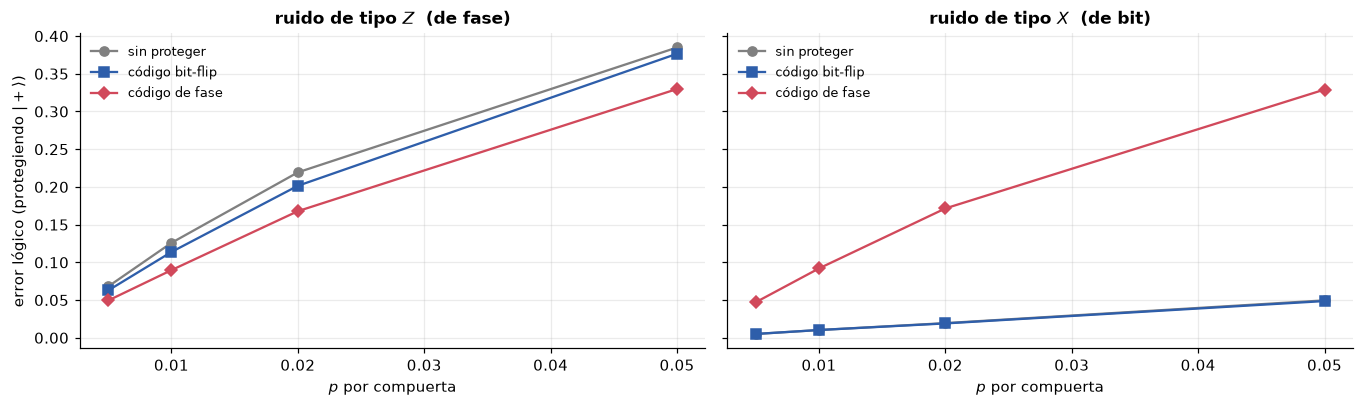

 ruido       p   sin proteger   cód. bit-flip    cód. fase
     Z   0.005         0.0680          0.0628       0.0495
     Z   0.010         0.1258          0.1138       0.0897
     Z   0.020         0.2193          0.2015       0.1678
     Z   0.050         0.3849          0.3765       0.3298
     X   0.005         0.0050          0.0051       0.0471
     X   0.010         0.0103          0.0103       0.0920
     X   0.020         0.0194          0.0191       0.1715
     X   0.050         0.0496          0.0487       0.3291


In [12]:
t_bf = transpile(codigo_fase("bitflip"), basis_gates=BASE_SIM, optimization_level=0)
t_pf = transpile(codigo_fase("phaseflip"), basis_gates=BASE_SIM, optimization_level=0)
t_d = transpile(desnudo(t_bf.depth(), base="X"), basis_gates=BASE_SIM,
                optimization_level=0)
S = 20000
ps2 = np.array([0.005, 0.01, 0.02, 0.05])
datos = {}
for pauli in ("Z", "X"):
    filas = []
    for p in ps2:
        simr = AerSimulator(noise_model=ruido_pauli(p, pauli))
        f = lambda t: sum(v for k, v in simr.run(t, shots=S).result()
                          .get_counts().items() if k.split()[0] == "1") / S
        filas.append((f(t_d), f(t_bf), f(t_pf)))
    datos[pauli] = np.array(filas)

fig, ejes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
for ax, pauli in zip(ejes, ("Z", "X")):
    m = datos[pauli]
    ax.plot(ps2, m[:, 0], "o-", ms=6, color="0.5", label="sin proteger")
    ax.plot(ps2, m[:, 1], "s-", ms=6, color=utils.COLOR_IDEAL, label="código bit-flip")
    ax.plot(ps2, m[:, 2], "D-", ms=6, color=utils.COLOR_RUIDO, label="código de fase")
    ax.set_xlabel("$p$ por compuerta")
    ax.set_title(f"ruido de tipo ${pauli}$" +
                 ("  (de fase)" if pauli == "Z" else "  (de bit)"))
    ax.legend(fontsize=8.5)
ejes[0].set_ylabel("error lógico (protegiendo $|+\\rangle$)")
utils.layout(fig)
plt.show()

print(f"{'ruido':>6} {'p':>7} {'sin proteger':>14} {'cód. bit-flip':>15} {'cód. fase':>12}")
for pauli in ("Z", "X"):
    for p, fila in zip(ps2, datos[pauli]):
        print(f"{pauli:>6} {p:>7.3f} {fila[0]:>14.4f} {fila[1]:>15.4f} {fila[2]:>12.4f}")

**Leé la tabla en cruz, que es donde está la lección.**

- Con ruido **$Z$**: el código de fase baja el error; el de bit-flip no hace
  prácticamente nada.
- Con ruido **$X$**: se da vuelta. Y el código de fase no solo no ayuda:
  **empeora el error unas 10 veces**.

Ese empeoramiento es estructural. El
código de fase entra a la base $X$ con Hadamards, y ahí los errores $X$ del
ambiente se convierten en errores $Z$ — que ese código no corrige y que
además
ahora se reparten entre tres qubits en vez de uno. **Protegerse de un tipo
de
error cuesta exponerse más al otro.**

### De ahí salen los 9 qubits de Shor

La salida es **concatenar**: tomar el código de fase y reemplazar cada uno
de
sus tres qubits por un bloque de tres qubits protegido contra bit-flips.
$3 \times 3 = 9$ qubits, y el resultado corrige **cualquier** error de un
qubit — $X$, $Z$, o $Y = iXZ$, y por linealidad también cualquier error
continuo.

Ese es el código de Shor de 1995, y es el primer código cuántico completo.
Los
códigos modernos (el **código de superficie**) usan la misma idea con una
geometría distinta, y necesitan del orden de **mil qubits físicos por qubit
lógico** para ser útiles. Con eso se entiende el número del notebook `09`:
los
20 millones de qubits físicos que pide RSA-2048.

---
# 6. QPE iterativa en un solo circuito

En el notebook `08` la QPE iterativa era el método bueno para NISQ
—profundidad constante, sin IQFT— pero tenía un costo escondido: cada bit
necesitaba **su propio job**, porque la corrección de fase dependía de los
bits ya medidos y eso se resolvía en Python.

Con `reset` y `if_test`, la realimentación ocurre **dentro del chip** y los
$n$
bits entran en un circuito.

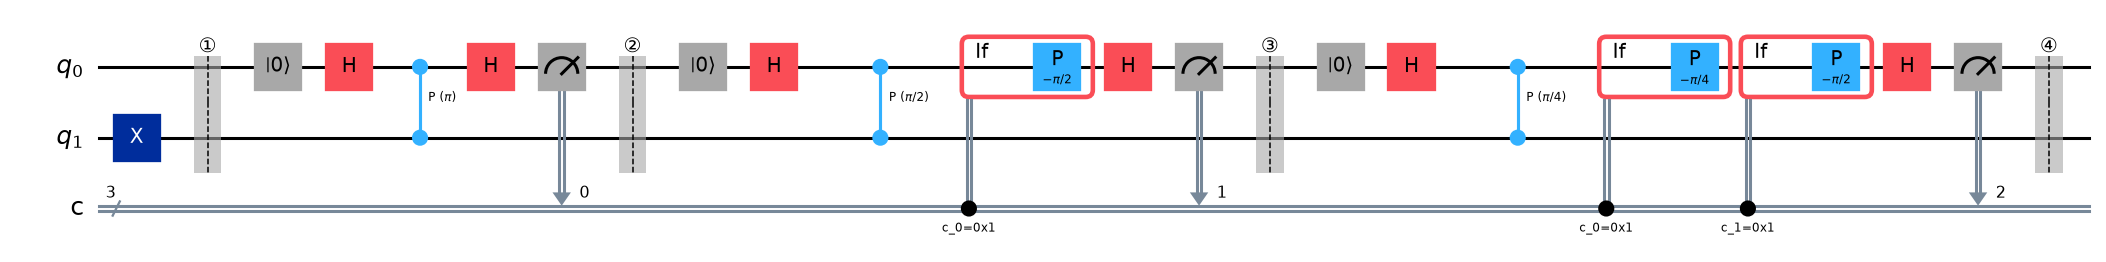

In [13]:
def qpe_iterativa_dinamica(phi: float, n_bits: int) -> QuantumCircuit:
    """QPE de Kitaev entera en un circuito: reset + feed-forward."""
    q = QuantumRegister(2, "q"); c = ClassicalRegister(n_bits, "c")
    qc = QuantumCircuit(q, c)
    theta = 2 * np.pi * phi
    qc.x(q[1])                                  # el autoestado de P(theta)
    marca(qc, 1)
    for j in range(n_bits):
        qc.reset(q[0])                          # reutilizar el qubit de conteo
        qc.h(q[0])
        qc.cp(theta * 2 ** (n_bits - 1 - j), q[0], q[1])
        for k in range(j):                      # corregir con lo ya medido
            with qc.if_test((c[k], 1)):
                qc.p(-2 * np.pi / 2 ** (j - k + 1), q[0])
        qc.h(q[0])
        qc.measure(q[0], c[j])
        marca(qc, min(j + 2, 9))
    return qc


display(qpe_iterativa_dinamica(0.125, 3).draw("mpl", style="iqp", fold=-1))

### La cuenta, etapa por etapa ($\varphi = 1/8$, tres bits)

Las barreras marcan el final de cada ronda. Seguimos el caso concreto
$\varphi = 1/8 = 0.001_2$, donde los tres bits tienen que salir
$\varphi_1\varphi_2\varphi_3 = 0,0,1$ (del más al menos significativo).

**①** Dado que se aplica $X$ al qubit de trabajo: queda en $|1\rangle$, que
es
autoestado de $P(\theta)$ con autovalor $e^{i\theta}$, o sea fase
$\varphi$. Ese qubit **no se toca más en todo el circuito**: solo presta su
fase por retroceso, ronda tras ronda.

**② — ronda 0, el bit MENOS significativo.** Se resetea el contador, se le
aplica $H$, y después $U^{4}$ controlada. El retroceso de fase deja al
contador
en
$$\frac{|0\rangle + e^{2\pi i \cdot 4\varphi}|1\rangle}{\sqrt2}
 = \frac{|0\rangle + e^{i\pi}|1\rangle}{\sqrt2} = |-\rangle ,$$
porque $4\varphi = 1/2$. La $H$ final manda $|-\rangle \to |1\rangle$ y la
medición da **$c_0 = 1$** con certeza. Ese es el último dígito de $0.001_2$.

La clave de por qué esto funciona: multiplicar $\varphi$ por $2^{n-1}$ hace
que
**todos los bits salvo el último se vuelvan múltiplos enteros de $2\pi$**, o
sea invisibles. La fase que queda es exactamente la del bit menos
significativo.

**③ — ronda 1.** Se **resetea** el contador (por eso alcanza un solo qubit)
y
se repite con $U^{2}$, que deja fase $2\pi \cdot 2\varphi = \pi/2$. Pero
ahora hay contaminación del bit ya conocido, así que se le resta:
la corrección condicionada por $c_0 = 1$ aplica $P(-\pi/2)$. Neto: fase
cero,
el contador vuelve a $|+\rangle$, y la medición da **$c_1 = 0$**.

**Esa corrección es el feed-forward**, y es lo que obliga a que el circuito
sea
dinámico: la compuerta que se aplica depende de un bit que todavía no
existía
cuando se compiló el circuito.

**④ — ronda 2, el bit MÁS significativo.** Igual, con $U^{1}$ (fase
$2\pi\varphi = \pi/4$) y las correcciones de $c_0$ y $c_1$ ya medidos. La
suma vuelve a dar cero y sale **$c_2 = 0$**.

### Cómo se lee el final

El registro queda $c_2c_1c_0 = 001$, y como $c_0$ es el bit **menos**
significativo y en la cadena de counts está a la derecha, **la cadena se lee
directo** como la fracción binaria:
$$0.c_2c_1c_0 = 0.001_2 = \tfrac18 = \varphi \;\checkmark$$

Y notemos el costo: el mismo qubit de conteo se usó tres veces gracias al
`reset`, y las tres rondas viven en **un solo circuito** en vez de tres
jobs.
Cada ronda tiene una sola $CU$, así que **la profundidad no crece con la
precisión** — que es exactamente lo que se quiere en NISQ.

In [14]:
print(f"\n{'φ':>8} {'bits leídos':>13} {'estimado':>10} {'error':>9} {'prob':>7}")
for phi, nb in [(0.125, 3), (0.375, 3), (0.8125, 4), (1 / 3, 5)]:
    c = utils.correr_ideal(qpe_iterativa_dinamica(phi, nb), shots=2048)
    bits = max(c, key=c.get)
    est = int(bits, 2) / 2 ** nb               # el registro se lee directo
    print(f"{phi:>8.4f} {bits:>13} {est:>10.4f} {abs(est - phi):>9.4f} "
          f"{c[bits] / 2048:>7.3f}")


       φ   bits leídos   estimado     error    prob


  0.1250           001     0.1250    0.0000   1.000
  0.3750           011     0.3750    0.0000   1.000


  0.8125          1101     0.8125    0.0000   1.000


  0.3333         01011     0.3438    0.0104   0.676


**El registro se lee directo**: el primer bit medido es el menos
significativo, y como cae en `c[0]` —que es el de más a la derecha en la
cadena— la cadena de counts ya es $0.c_{n-1}\ldots c_0$ en binario.

### El ahorro, en segundos de QPU

Acá está el punto práctico. Con el presupuesto del curso —10 minutos por
ventana de 28 días, y **~2.5 s de overhead fijo por job**— la diferencia
entre
$n$ jobs y uno no es cosmética.

In [15]:
OVERHEAD, REP_DELAY, SHOTS_HW = 2.5, 250e-6, 1024
print(f"{'bits':>5} {'jobs (08)':>11} {'QPU (08)':>11} {'jobs (10)':>11} "
      f"{'QPU (10)':>11} {'ahorro':>9}")
for nb in (3, 4, 5, 6, 8):
    viejo = nb * (OVERHEAD + SHOTS_HW * REP_DELAY)
    nuevo = OVERHEAD + SHOTS_HW * REP_DELAY
    print(f"{nb:>5} {nb:>11} {viejo:>10.1f}s {1:>11} {nuevo:>10.1f}s "
          f"{viejo / nuevo:>8.1f}×")
print("\n(el circuito dinámico es más largo y más ruidoso: el ahorro es de")
print(" tiempo de cola y de cuota, no de fidelidad)")

 bits   jobs (08)    QPU (08)   jobs (10)    QPU (10)    ahorro
    3           3        8.3s           1        2.8s      3.0×
    4           4       11.0s           1        2.8s      4.0×
    5           5       13.8s           1        2.8s      5.0×
    6           6       16.5s           1        2.8s      6.0×
    8           8       22.0s           1        2.8s      8.0×

(el circuito dinámico es más largo y más ruidoso: el ahorro es de
 tiempo de cola y de cuota, no de fidelidad)


---
# 7. El cronograma real del chip

Todo lo anterior asume que sabemos cuánto tardan las cosas. La tabla de la
§1
sale del *target*, y cubre las compuertas — pero **no dice cuánto tarda el
chip
en decidir**. Entre que la medición termina y la compuerta condicionada
arranca hay un tiempo muerto: viajar al procesador clásico, evaluar la
condición, y volver. Durante todo ese rato los qubits decoheran.

Ese número no está en ninguna tabla y **no se puede simular**: lo arma el
compilador de IBM. Pero se puede pedir, con un flag experimental:

```python
sampler.options.experimental = {"execution": {"scheduler_timing": True}}
```

y al volver el job queda en
`result[0].metadata["compilation"]["scheduler_timing"]["timing"]`: una lista
de
strings con `Branch, Instruction, Channel, T0, Duration`, con los tiempos en
unidades de `dt`.

Tres cosas salen de ahí, y las tres importan:

1. **La latencia de decisión**, restando el arranque de la primera
instrucción
   condicionada del fin de la última medición.
2. **La duración real del circuito**, para comparar contra $T_2$ y contra el
   modelo de costo que venimos usando.
3. **Los canales de lectura**, que vienen como `AWGR<instrumento>_<qubit>`:
los
   qubits que comparten instrumento **comparten feedline**. Eso explica por
     qué
   no se puede medir cualquier subconjunto de qubits en paralelo sin que se
   afecten entre sí — y por qué IBM no reparte tus shots entre qubits.

`utils.py` trae el parser, el resumen y un diagrama de Gantt. Los probamos
con
un ejemplo sintético del formato documentado, para que cuando llegue el job
de
verdad no haya sorpresas.

etiquetas de rama encontradas: ['main', 'then'] 
  (si alguna que NO sea condicional quedó marcada con borde, revisá es_condicional en utils.resumen_timing)


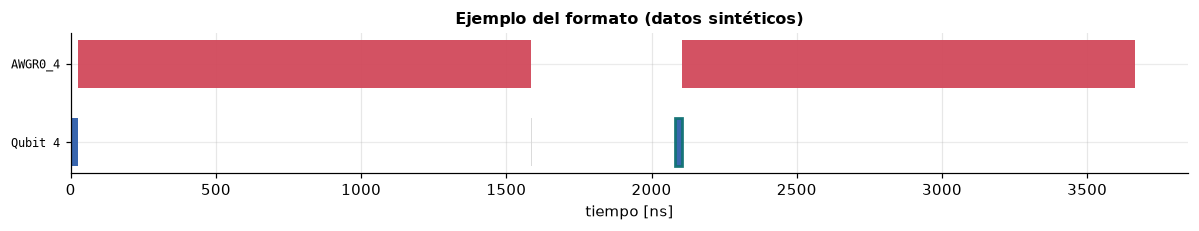

  DATOS SINTÉTICOS — los inventé yo para probar el parser.
  Los tiempos reales solo salen de un job mandado al chip.
duración total       : 3.66 µs
medición típica      : 1560 ns   ← este sí coincide con el target real
latencia de decisión : 496 ns (124 dt)   ← INVENTADO
canales              : ['AWGR0_4', 'Qubit 4']
etiquetas de rama    : ['main', 'then']


In [16]:
ejemplo = [
    "main, h Qubit 4, Qubit 4, 0, 6",
    "main, measure Qubit 4, AWGR0_4, 6, 390",
    "main, barrier, Qubit 4, 396, 0",
    "then, x Qubit 4, Qubit 4, 520, 6",
    "main, measure Qubit 4, AWGR0_4, 526, 390",
]
filas = utils.parsear_timing(ejemplo)
resumen = utils.resumen_timing(filas, dt=fez.dt)

fig, ax = plt.subplots(figsize=(11, 2.2))
utils.dibujar_timing(filas, dt=fez.dt, ax=ax,
                     titulo="Ejemplo del formato (datos sintéticos)")
utils.layout(fig)
plt.show()

print("=" * 62)
print("  DATOS SINTÉTICOS — los inventé yo para probar el parser.")
print("  Los tiempos reales solo salen de un job mandado al chip.")
print("=" * 62)
print(f"duración total       : {resumen['duracion_total_s'] * 1e6:.2f} µs")
print(f"medición típica      : {resumen['medicion_s'] * 1e9:.0f} ns   "
      f"← este sí coincide con el target real")
print(f"latencia de decisión : {resumen['latencia_decision_s'] * 1e9:.0f} ns "
      f"({resumen['latencia_decision_dt']} dt)   ← INVENTADO")
print(f"canales              : {resumen['canales']}")
print(f"etiquetas de rama    : {resumen['etiquetas_de_rama']}")

**Los números de arriba son inventados.** Las cinco líneas del ejemplo las
escribir a mano para verificar que el parser funciona; la "latencia de
decisión
de 496 ns" es aritmética de datos falsos, no una medición. **Nadie sabe
cuánto
tarda de verdad hasta mandar el job** — ese es exactamente el motivo del
flag.

Lo único real de ese bloque es la duración de la medición (1560 ns), que la
puse igual al target para que el ejemplo fuera verosímil.

Hay una segunda incertidumbre, más chica: el **orden** de los campos está
documentado, pero las **etiquetas** de rama (`main`, `then`) las supuse. Por
eso `resumen_timing` devuelve `etiquetas_de_rama`: cuando llegue un job
real,
lo primero es mirar esa lista y confirmar que el detector de instrucciones
condicionadas está acertando.

---
# 8. Hardware real

Tres circuitos en un job, y el flag de timing activado. Con eso se llevan de
una sola corrida: el código de corrección funcionando (o no) en el chip, la
QPE iterativa dinámica, y **el cronograma real de los tres**.

In [17]:
if service is not None:
    print(f"{'backend':<16} {'qubits':>6} {'cola':>6}  {'estado':<10}")
    print("-" * 46)
    for b in service.backends(simulator=False):
        st = b.status()
        print(f"{b.name:<16} {b.num_qubits:>6} {st.pending_jobs:>6}  {st.status_msg:<10}")
else:
    print("sin autenticar")

sin autenticar


In [18]:
BACKEND_FIJO = None

backend = None
if service is not None:
    backend = (service.backend(BACKEND_FIJO) if BACKEND_FIJO
               else service.least_busy(operational=True, simulator=False))
    st = backend.status()
    print(f"elegido: {backend.name}  ·  {st.status_msg}  ·  cola {st.pending_jobs}")
    print("¿soporta control de flujo?",
          [o for o in ("if_else", "switch_case", "for_loop", "reset")
           if o in backend.target.operation_names])
else:
    print("sin autenticar: no hay backend")

sin autenticar: no hay backend


In [19]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

SHOTS_HW = 4096
CASOS_HW = [
    ("cod_sin_error", codigo_bitflip(0.9, None, True)),
    ("cod_error_q1", codigo_bitflip(0.9, 1, True)),
    ("cod_sin_corregir", codigo_bitflip(0.9, 1, False)),
    ("qpe_dinamica_3bits", qpe_iterativa_dinamica(0.125, 3)),
    ("reset_4_monedas", con_reset(4)),
]
t_din = None
if backend is not None:
    pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
    t_din = pm.run([c for _, c in CASOS_HW])
    print("=== circuitos dinámicos: 5 circuitos en un job ===")
    costo = utils.informe_transpilacion(t_din, shots=SHOTS_HW,
                                        nombre_backend=backend.name)
else:
    print("sin backend: nada que transpilar")

sin backend: nada que transpilar


### El envío

`PEDIR_TIMING` agrega el flag experimental. No cuesta QPU extra: es metadata
del mismo job.

In [20]:
ENVIAR_DINAMICOS = False    # ponerlo en True para gastar QPU
PEDIR_TIMING = True         # metadata del cronograma; no cuesta nada aparte

if ENVIAR_DINAMICOS:
    from qiskit_ibm_runtime import SamplerV2

    sampler = SamplerV2(mode=backend)
    if PEDIR_TIMING:
        utils.pedir_timing(sampler.options)
        print("scheduler_timing activado")
    job = sampler.run(t_din, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"10 dinamicos: correccion + QPE iterativa + reset, {SHOTS_HW} shots",
                        notebook="10", experimento="dinamicos",
                        n_circuitos=len(t_din), shots=SHOTS_HW,
                        timing=PEDIR_TIMING,
                        orden=[n for n, _ in CASOS_HW])
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


In [21]:
registros = utils.listar_jobs(filtro="10 ")

In [22]:
JOB_ID = ""   # vacío = el último job de circuitos dinámicos

if not JOB_ID:
    reg = utils.ultimo_job(experimento="dinamicos")
    JOB_ID = reg["job_id"] if reg else ""
    if reg:
        print(f"último: {JOB_ID}  ({reg['backend']}, {reg['fecha']})")

if JOB_ID and service is not None:
    resultado = utils.recuperar(service, JOB_ID).result()
    hw = [utils.counts_de_resultado(resultado, i) for i in range(len(resultado))]

    fig, ejes = plt.subplots(1, 3, figsize=(13.5, 3.4))
    for ax, (nombre, _), c in zip(ejes, CASOS_HW[:3], hw[:3]):
        sind = {}
        for k, v in c.items():
            s = k.split()[1] if " " in k else k
            sind[s] = sind.get(s, 0) + v
        utils.comparar_conteos({"hardware": sind}, claves=["00", "01", "11", "10"],
                               ax=ax, titulo=nombre)
        ax.set_xlabel("síndrome")
    utils.layout(fig)
    plt.show()

    for (nombre, _), c in zip(CASOS_HW, hw):
        n = sum(c.values())
        fallo = sum(v for k, v in c.items() if k.split()[0] == "1") / n
        print(f"{nombre:<22} fallo lógico = {fallo:.4f}")
else:
    hw = None
    print("sin JOB_ID o sin autenticar: nada que recuperar")

sin JOB_ID o sin autenticar: nada que recuperar


In [23]:
if JOB_ID and service is not None and hw is not None:
    filas_hw, comp = utils.timing_de_resultado(resultado, 1)   # el del error en q1
    if filas_hw:
        r = utils.resumen_timing(filas_hw, dt=backend.dt)
        fig, ax = plt.subplots(figsize=(13, 0.45 * len(r["canales"]) + 2))
        utils.dibujar_timing(filas_hw, dt=backend.dt, ax=ax,
                             titulo="Cronograma REAL del código de corrección")
        utils.layout(fig)
        plt.show()

        print(f"duración del circuito : {r['duracion_total_s'] * 1e6:.2f} µs")
        print(f"medición              : {r.get('medicion_s', 0) * 1e9:.0f} ns")
        if "latencia_decision_s" in r:
            lat = r["latencia_decision_s"]
            print(f"latencia de decisión  : {lat * 1e9:.0f} ns   "
                  f"= {lat / duraciones['sx']:.0f} compuertas de un qubit")
            print(f"                        = {lat / t2:.2%} del T2 del chip")
        lectura = [c for c in r["canales"] if c.startswith("AWGR")]
        print(f"canales de lectura    : {lectura}")
        print("  (los que comparten el mismo instrumento comparten feedline)")
        print(f"\nduración total / T2   : {r['duracion_total_s'] / t2:.2%}")
else:
    print("(esta figura se llena cuando recuperes un job con PEDIR_TIMING = True)")

(esta figura se llena cuando recuperes un job con PEDIR_TIMING = True)


---
## Qué quedó establecido

1. **El chip soporta control de flujo de verdad**: `if_else`, `switch_case`,
   `for_loop` y `reset` están en su set de instrucciones. No hay
     `while_loop`,
   así que no hay repetición no acotada.
2. **Una medición cuesta como 65 compuertas de un qubit** (1560 ns contra
   24 ns). Ese es el presupuesto real de un circuito dinámico.
3. **Se corrige sin clonar** midiendo *paridades*: el síndrome informa sobre
el
   error y no sobre el estado, así que no colapsa la superposición.
4. **Con síndrome perfecto, el error lógico va como $3p^2$** contra $p$ del
   qubit desnudo: cuadrático le gana a lineal.
5. **Cada código de 3 qubits protege un tipo de error y empeora el otro**
—el
   de fase es 10× peor bajo ruido $X$—, y de ahí salen los 9 qubits de Shor
     y
   los ~1000 del código de superficie.
6. **La QPE iterativa entra en un solo job** con `reset` + feed-forward:
   de $n$ jobs a uno, lo que con 6 bits son 15 s de cuota contra 2.8 s.
7. **El cronograma real** (`scheduler_timing`) da el número que ninguna
tabla
   tiene: cuánto tarda el chip en decidir, y qué qubits comparten feedline.

**Fin de la serie ampliada:** `01` → `01b` → `02` → `03` → `04` → `05` →
`06`
→ `07` → `08` → `09` → `10`.